# Ejercicio Python de Regresión Logística
Realizaremos un ejercicio de prueba para comprender como funciona este algoritmo

In [ ]:
import pandas as pd
import numpy as np
from sklearn import linear_model
from sklearn import model_selection
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

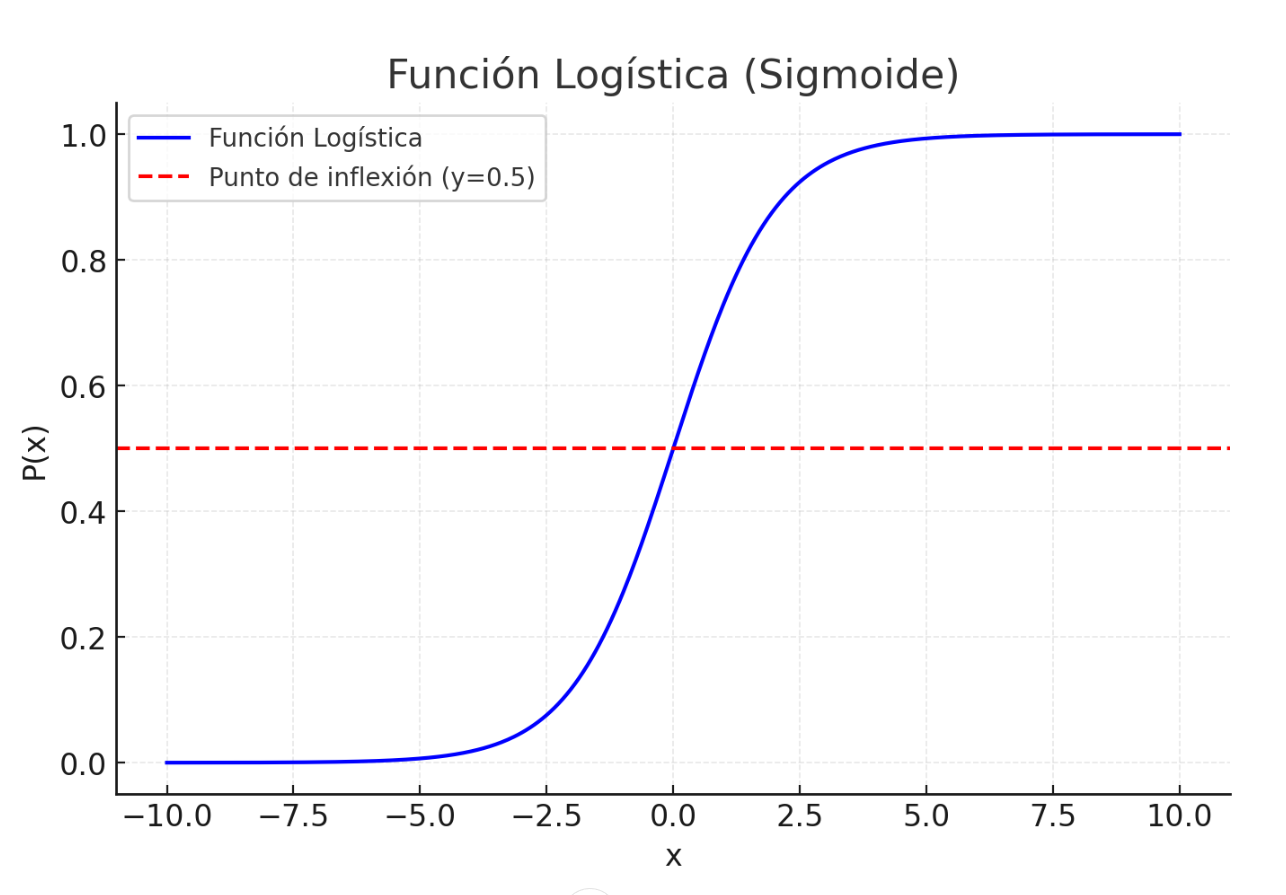

## Cargamos los datos de entrada del archivo csv

In [ ]:
dataframe = pd.read_csv("data/usuarios_win_mac_lin.csv")

clases = {
    0: 'Windows',
    1: 'Linux',
    2: 'Mac'
}

dataframe.head()

In [ ]:
dataframe['clase'].value_counts(normalize=True)

In [ ]:
dataframe['clase'].value_counts()

In [ ]:
dataframe.describe()

In [ ]:
sns.boxplot(x= dataframe['duracion']);

In [ ]:
sns.histplot(dataframe['duracion'], kde=True);

In [ ]:
dataframe.info()

In [ ]:
print(dataframe.groupby('clase').size())

## Visualizamos los datos

In [ ]:
dataframe.drop('clase', axis=1).hist()
plt.show()

In [ ]:
sns.pairplot(dataframe.dropna(),
            hue='clase',
            height=4,
            vars=["duracion", "paginas","acciones","valor"],
            kind='reg'); # "reg" de regresión lineal

## Creamos el modelo

In [ ]:
X = np.array(dataframe.drop(columns=['clase']))
y = np.array(dataframe['clase'])

In [ ]:
X = dataframe.drop("clase",axis=1).values
y = dataframe["clase"].values

In [ ]:
X

In [ ]:
y

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
model = LogisticRegression(max_iter=1000)
model.fit(X, y)

In [ ]:
predictions = model.predict(X)
print(predictions)

In [ ]:
predicions_proba = model.predict_proba(X)
print(np.round(np.array(predicions_proba), 2))
#predicions_proba

In [ ]:
model.score(X, y)

In [ ]:
model.classes_

# Validación del Modelo

In [ ]:
validation_size = 0.20
seed = 7
X_train, X_test, Y_train, Y_test = model_selection.train_test_split(X,
                                                                    y,
                                                                    test_size=validation_size,
                                                                    random_state=seed)

In [ ]:
name='Logistic Regression'
kfold = model_selection.KFold(n_splits=10) #Parte los datos en 10 trozos para usar validación cruzada / cross validation
cv_results = model_selection.cross_val_score(model, X_train, Y_train, cv=kfold, scoring='accuracy')

msg = "%s: %f (%f)" % (name, cv_results.mean(), cv_results.std())
print(cv_results)
print(msg)

In [ ]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, Y_train)

## Resultados

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score

In [ ]:
predictions = model.predict(X_test)
print(accuracy_score(Y_test, predictions))
predictions

In [ ]:
acierto = accuracy_score(Y_test, predictions)

error = 1 - acierto
print("Acierto:", round(acierto*100, 2), "%")
print("Error:", round(error*100, 2), "%")

In [ ]:
c_matrix = confusion_matrix(Y_test, predictions)

In [ ]:
print(c_matrix)

In [ ]:
import seaborn as sns
sns.heatmap(c_matrix, annot=True);

In [ ]:
sns.heatmap(confusion_matrix(Y_test, predictions, normalize='true'), annot=True, 
            fmt='.2%', cmap='Blues');

In [ ]:
from sklearn.metrics import multilabel_confusion_matrix, precision_score, recall_score, f1_score

multilabel_confusion_matrix(Y_test, predictions)

Una matriz de confusión para cada clase

[Nice confusion matrix catalog visuals examples](https://medium.com/@dtuk81/confusion-matrix-visualization-fc31e3f30fea)

In [ ]:
sns.heatmap(multilabel_confusion_matrix(Y_test, predictions)[2], annot=True);

# Clasificación de nuevos registros

In [ ]:
X_new = pd.DataFrame({'duracion': [8],
                     'paginas': [5],
                     'acciones': [5],
                     'valor': [2]})
X_new

In [ ]:
X_new.values

In [ ]:
model.predict(X_new.values)

In [ ]:
model.predict_proba(X_new.values)